### Load CSV

In [57]:
import pandas as pd

movies = pd.read_csv("../dataset/movies.csv")

print(movies.head())
print(movies.shape)
print(movies.columns)
print(movies.info())

   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  
(9742, 3)
Index(['movieId', 'title', 'genres'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  9742 non-null   int64
 1   title    9742 non-null   str  
 2   genres   9742 non-null   str  
dtypes: int64(1), str(2)
memory usage: 626.1 KB
None


### Missing Values

In [58]:
# Check missing values
print(movies.isnull().sum())

movieId    0
title      0
genres     0
dtype: int64


### Check duplicates

In [59]:
# check duplicate records
print("Duplicate rows:", movies.duplicated().sum())

# Check duplicate movie IDs
print("Duplicate movie IDs:", movies['movieId'].duplicated().sum())

# Check for duplicate movie titles
print("Duplicate movie titles:", movies['title'].duplicated().sum())

Duplicate rows: 0
Duplicate movie IDs: 0
Duplicate movie titles: 5


In [60]:
# Get all unique genres from the 'genres' column
all_genres = movies['genres'].str.split('|').explode().unique()

print("All unique genres:", all_genres)

All unique genres: <ArrowStringArray>
[         'Adventure',          'Animation',           'Children',
             'Comedy',            'Fantasy',            'Romance',
              'Drama',             'Action',              'Crime',
           'Thriller',             'Horror',            'Mystery',
             'Sci-Fi',                'War',            'Musical',
        'Documentary',               'IMAX',            'Western',
          'Film-Noir', '(no genres listed)']
Length: 20, dtype: str


In [61]:
# count the number of movies in each genre
genre_counts = movies['genres'].str.split('|').explode().value_counts()
print("Number of movies in each genre:", genre_counts)

Number of movies in each genre: genres
Drama                 4361
Comedy                3756
Thriller              1894
Action                1828
Romance               1596
Adventure             1263
Crime                 1199
Sci-Fi                 980
Horror                 978
Fantasy                779
Children               664
Animation              611
Mystery                573
Documentary            440
War                    382
Musical                334
Western                167
IMAX                   158
Film-Noir               87
(no genres listed)      34
Name: count, dtype: int64


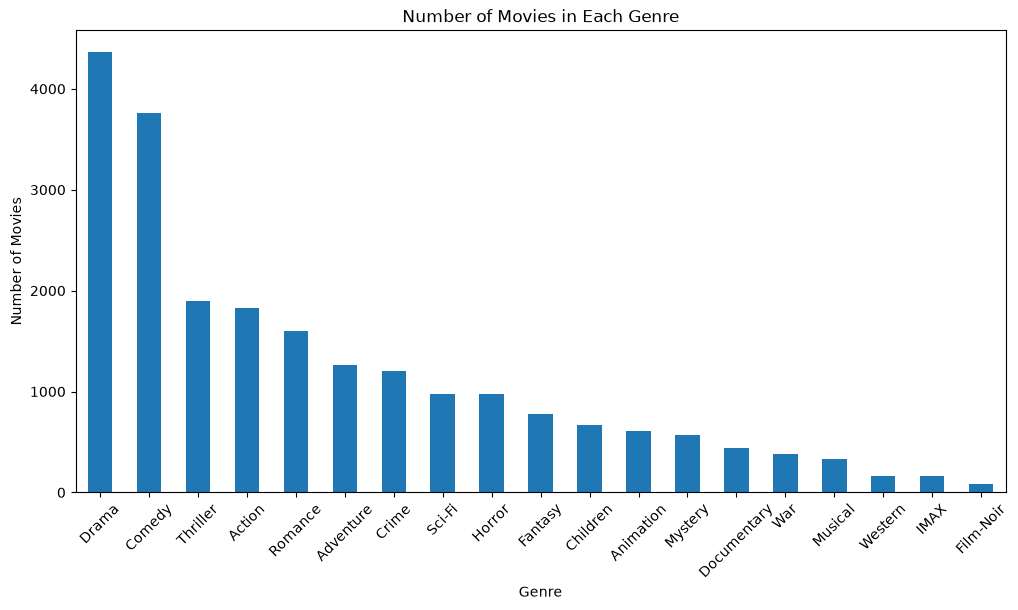

In [62]:
import matplotlib.pyplot as plt

genre_counts.drop('(no genres listed)', errors='ignore').plot(kind='bar', figsize=(12, 6))

plt.title('Number of Movies in Each Genre')
plt.xlabel('Genre')
plt.ylabel('Number of Movies')
plt.xticks(rotation=45)
plt.show()

### Feature engineering- Adding tags

In [63]:
# Load Tag Dataset
tags = pd.read_csv("../dataset/tags.csv")

# Display the first 5 rows
print(tags.head())

# Check the dataset information
print(tags.shape)
print(tags.columns)
print(tags.info())


   userId  movieId              tag   timestamp
0       2    60756            funny  1445714994
1       2    60756  Highly quotable  1445714996
2       2    60756     will ferrell  1445714992
3       2    89774     Boxing story  1445715207
4       2    89774              MMA  1445715200
(3683, 4)
Index(['userId', 'movieId', 'tag', 'timestamp'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 3683 entries, 0 to 3682
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   userId     3683 non-null   int64
 1   movieId    3683 non-null   int64
 2   tag        3683 non-null   str  
 3   timestamp  3683 non-null   int64
dtypes: int64(3), str(1)
memory usage: 151.7 KB
None


In [64]:
# Group tags by movieId and aggregate the tags into a list
movie_tags = tags.groupby('movieId')['tag'].apply(
    lambda x: ''.join(x.dropna().astype(str).unique())
).reset_index()

print(movie_tags.head())

   movieId                                        tag
0        1                                   pixarfun
1        2  fantasymagic board gameRobin Williamsgame
2        3                                   moldyold
3        5                            pregnancyremake
4        7                                     remake


In [65]:
# merge movies and tags
movies = movies.merge(movie_tags, on='movieId', how='left') # left join to keep all movies even if they don't have tags

# replace missing tags with an empty string
movies['tag'] = movies['tag'].fillna('')

print(movies.head())

   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  \
0  Adventure|Animation|Children|Comedy|Fantasy   
1                   Adventure|Children|Fantasy   
2                               Comedy|Romance   
3                         Comedy|Drama|Romance   
4                                       Comedy   

                                         tag  
0                                   pixarfun  
1  fantasymagic board gameRobin Williamsgame  
2                                   moldyold  
3                                             
4                            pregnancyremake  


In [66]:
# clean genres column by replacing '(no genres listed)' with an empty string
movies['genres'] = movies['genres'].replace('(no genres listed)', '')

# combine genres and tags
movies['combined_features'] = (
    movies['genres'].str.replace('|', ' ', regex=False)
    + ' ' + movies['tag']
).str.lower().str.strip()

print(movies[['title', 'genres', 'tag', 'combined_features']].head())

                                title  \
0                    Toy Story (1995)   
1                      Jumanji (1995)   
2             Grumpier Old Men (1995)   
3            Waiting to Exhale (1995)   
4  Father of the Bride Part II (1995)   

                                        genres  \
0  Adventure|Animation|Children|Comedy|Fantasy   
1                   Adventure|Children|Fantasy   
2                               Comedy|Romance   
3                         Comedy|Drama|Romance   
4                                       Comedy   

                                         tag  \
0                                   pixarfun   
1  fantasymagic board gameRobin Williamsgame   
2                                   moldyold   
3                                              
4                            pregnancyremake   

                                   combined_features  
0  adventure animation children comedy fantasy pi...  
1  adventure children fantasy fantasymagic board ... 

In [67]:
print(movies[['title', 'combined_features']].tail())

                                          title  \
9737  Black Butler: Book of the Atlantic (2017)   
9738               No Game No Life: Zero (2017)   
9739                               Flint (2017)   
9740        Bungo Stray Dogs: Dead Apple (2018)   
9741        Andrew Dice Clay: Dice Rules (1991)   

                    combined_features  
9737  action animation comedy fantasy  
9738         animation comedy fantasy  
9739                            drama  
9740                 action animation  
9741                           comedy  


### TF-IDF Vectorization

In [68]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer(stop_words='english')

# Convert movie text into numerical feature vectors
tfidf_matrix = tfidf_vectorizer.fit_transform(movies['combined_features'])

print("Number of movies:", tfidf_matrix.shape[0])
print("Number of features:", tfidf_matrix.shape[1])
print(tfidf_matrix)

Number of movies: 9742
Number of features: 1958
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 26206 stored elements and shape (9742, 1958)>
  Coords	Values
  (0, 74)	0.2541574044961174
  (0, 130)	0.31475083990018826
  (0, 426)	0.30706188885509844
  (0, 480)	0.16315170996012543
  (0, 784)	0.2944867341288348
  (0, 1407)	0.7929110933098883
  (1, 74)	0.1529726579092923
  (1, 426)	0.1848148920702787
  (1, 784)	0.1772461381875779
  (1, 787)	0.47723857453552726
  (1, 296)	0.47723857453552726
  (1, 885)	0.47723857453552726
  (1, 1933)	0.47723857453552726
  (2, 480)	0.19357451935394585
  (2, 1554)	0.27837119058173077
  (2, 1244)	0.9407647876653326
  (3, 480)	0.5050154397005037
  (3, 1554)	0.726240982959826
  (3, 691)	0.46640480307738325
  (4, 480)	0.20154070370472826
  (4, 1442)	0.9794801400488948
  (5, 39)	0.5494290134121249
  (5, 565)	0.6356805133133094
  (5, 1804)	0.5422527493841841
  (6, 480)	0.21153943209487852
  :	:
  (9731, 1594)	0.5089434260856879
  (9731, 806)	0.5089434

### Cosine Similarity

In [69]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(tfidf_matrix)
print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix shape: (9742, 9742)


In [70]:
# check similarity between first 5 movies
print(similarity_matrix[:5, :5])

# find the index of a movie by its title
movie_index = movies[movies['title'] == 'Toy Story (1995)'].index[0]

print("Index of 'Toy Story (1995)':", movie_index)
print("Movie Name:", movies.loc[movie_index, 'title'])

[[1.         0.14782538 0.03158201 0.08239413 0.03288171]
 [0.14782538 1.         0.         0.         0.        ]
 [0.03158201 0.         1.         0.29992269 0.03901314]
 [0.08239413 0.         0.29992269 1.         0.10178117]
 [0.03288171 0.         0.03901314 0.10178117 1.        ]]
Index of 'Toy Story (1995)': 0
Movie Name: Toy Story (1995)


### Find Similar Movies

In [71]:
# Get similarity scrores for Toy Story (1995)
similarity_scores = list(enumerate(similarity_matrix[movie_index]))

# Sort the movies based on similarity scores
sorted_movies = sorted(similarity_scores, key=lambda x: x[1], reverse=True)

# Display top 10 similar movies
for movie in sorted_movies[1:11]:  # Skip the first one as it is the movie itself
    index = movie[0]
    score = movie[1]
    print(f"Movie: {movies.loc[index, 'title']}, Similarity Score: {score:.4f}")

Movie: Antz (1998), Similarity Score: 0.6093
Movie: Adventures of Rocky and Bullwinkle, The (2000), Similarity Score: 0.6093
Movie: Emperor's New Groove, The (2000), Similarity Score: 0.6093
Movie: Monsters, Inc. (2001), Similarity Score: 0.6093
Movie: Wild, The (2006), Similarity Score: 0.6093
Movie: Shrek the Third (2007), Similarity Score: 0.6093
Movie: Tale of Despereaux, The (2008), Similarity Score: 0.6093
Movie: Asterix and the Vikings (Astérix et les Vikings) (2006), Similarity Score: 0.6093
Movie: Turbo (2013), Similarity Score: 0.6093
Movie: The Good Dinosaur (2015), Similarity Score: 0.6093


In [72]:
def recommend_movies(movie_title, top_n = 5):

    # Find movie index
    movie_index = movies[
        movies['title'].str.lower() == movie_title.lower()
    ].index[0]

    # Get similarity scores for the given movie
    similarity_scores = list(enumerate(similarity_matrix[movie_index]))

    # Sort the movies based on similarity scores
    sorted_movies = sorted(similarity_scores, key=lambda x: x[1], reverse=True)

    # Exclude the first movie (itself) and get top N recommendations
    recommended_movies = sorted_movies[1:top_n + 1]

    # return recommended_movies

    # Display recommended movies
    print(f"Top {top_n} recommended movies for '{movie_title}':")
    for movie in recommended_movies:
        index = movie[0]
        score = movie[1]
        print(f"Movie: {movies.loc[index, 'title']}, Similarity Score: {score:.4f}")

In [73]:
recommend_movies('Toy Story (1995)', 5)

Top 5 recommended movies for 'Toy Story (1995)':
Movie: Antz (1998), Similarity Score: 0.6093
Movie: Adventures of Rocky and Bullwinkle, The (2000), Similarity Score: 0.6093
Movie: Emperor's New Groove, The (2000), Similarity Score: 0.6093
Movie: Monsters, Inc. (2001), Similarity Score: 0.6093
Movie: Wild, The (2006), Similarity Score: 0.6093


In [74]:
recommend_movies('Jumanji (1995)', 5)

Top 5 recommended movies for 'Jumanji (1995)':
Movie: Indian in the Cupboard, The (1995), Similarity Score: 0.2983
Movie: NeverEnding Story III, The (1994), Similarity Score: 0.2983
Movie: Escape to Witch Mountain (1975), Similarity Score: 0.2983
Movie: Darby O'Gill and the Little People (1959), Similarity Score: 0.2983
Movie: Return to Oz (1985), Similarity Score: 0.2983


In [75]:
recommend_movies('Jurassic Park (1993)', 5)

Top 5 recommended movies for 'Jurassic Park (1993)':
Movie: Escape from L.A. (1996), Similarity Score: 0.5775
Movie: Abyss, The (1989), Similarity Score: 0.5775
Movie: Escape from New York (1981), Similarity Score: 0.5775
Movie: Spawn (1997), Similarity Score: 0.5775
Movie: Total Recall (1990), Similarity Score: 0.5775
